In [ ]:
import copy

import torch
from torch import nn, optim
import matplotlib.pyplot as plt
import numpy as np

from pkg.data_utils import preprocess_data

print("imports done")


imports done


Training in progress
MSE: 0.02
RMSE: 0.14


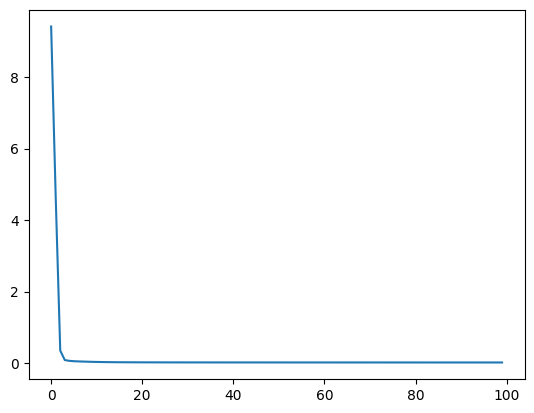

tensor([ 1.5590, -1.9548, -0.8078,  0.1173, -1.5147, -0.5780,  0.0000,  0.0000,
         0.0000,  0.0000,  1.0000,  0.0000,  0.0000,  1.0000,  0.0000,  0.0000,
         1.0000,  0.0000,  0.0000,  0.0000,  1.0000]) -> [2.4508119] (expected [2.582])
tensor([ 1.5590, -0.4473, -0.6471, -1.1363,  0.1662,  0.0917,  1.0000,  0.0000,
         0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  1.0000,  0.0000,
         1.0000,  0.0000,  0.0000,  0.0000,  1.0000]) -> [3.1863692] (expected [3.452])
tensor([-0.6362, -0.5661,  0.7056,  1.3709,  0.1662,  0.4788,  1.0000,  0.0000,
         0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  1.0000,  0.0000,  0.0000,
         0.0000,  0.0000,  1.0000,  1.0000,  0.0000]) -> [2.9415045] (expected [3.035])
tensor([ 0.0956, -1.3105, -0.1230, -1.1363, -1.5147, -1.9756,  0.0000,  0.0000,
         0.0000,  1.0000,  0.0000,  1.0000,  0.0000,  0.0000,  0.0000,  0.0000,
         0.0000,  1.0000,  0.0000,  0.0000,  1.0000]) -> [2.583411] (expected [2.754])
tensor([-

In [ ]:
(print("Training in progress"))
X_train, X_test, y_train, y_test = preprocess_data()
#print(list(X_train.columns))

X_train = torch.tensor(X_train.to_numpy(), dtype=torch.float32)
y_train = torch.tensor(y_train.to_numpy(), dtype=torch.float32).reshape(-1, 1)
X_test = torch.tensor(X_test.to_numpy(), dtype=torch.float32)
y_test = torch.tensor(y_test.to_numpy(), dtype=torch.float32).reshape(-1, 1)

#Seed model for repeatable results
torch.manual_seed(42)

# Define the model - Experiment with this block
model = nn.Sequential(
    nn.Linear(X_train.shape[1], 24),
    nn.ReLU(),
    nn.Linear(24, 12),
    nn.ReLU(),
    nn.Linear(12, 6),
    nn.ReLU(),
    nn.Linear(6, 1),
)

loss_fn = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=0.0001) #updates the model's parameters during training to minimize the loss function

n_epochs = 50 # number of passes through the training data
batch_size = 128 # model averages errors over grouped data not individua students
batch_start = torch.arange(0, len(X_train), batch_size)

#lowest error seen so far
best_mse = np.inf

# model params from that epoch
best_weights = None

#list of epoch errors?
history = []

for epoch in range(n_epochs):
    model.train()
    for start in batch_start:
        # take a batch
        X_batch = X_train[start:start+batch_size]
        y_batch = y_train[start:start+batch_size]
        # forward pass: pushing the batch through the network to get predictions. One prediction per batch
        y_pred = model(X_batch)
        loss = loss_fn(y_pred, y_batch)
        # backward pass
        optimizer.zero_grad()
        
        #trace error back to see how much each weight contributed to it
        loss.backward()
        
        # update/nudge weights
        optimizer.step()
    # evaluate accuracy at end of each epoch
    model.eval()
    y_pred = model(X_test)
    mse = loss_fn(y_pred, y_test)
    mse = float(mse)
    history.append(mse)
    if mse < best_mse:
        best_mse = mse
        best_weights = copy.deepcopy(model.state_dict())
 
model.load_state_dict(best_weights)
print("MSE: %.4f" % best_mse)
print("RMSE: %.4f" % np.sqrt(best_mse))
plt.plot(history)
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.title("Neural network MSE per epoch")
plt.show()

model.eval()
with torch.no_grad():
    # Test out inference with 5 samples
    for i in range(5):
        y_pred = model(X_test[i:i+1])
        print(f"{X_test[i]} -> {y_pred[0].numpy()} (expected {y_test[i].numpy()})")

